# NGT MHA (standard multi-head attention) Full-Precision aligned Collide-2V workflow

Alignment points for the Meeting 29.06:

- Builds a raw per-event tensor with **5 particle features**: `pt`, `eta`, `phi`, `dxy/D0`, `pdgId/PID`.
- Computes normalization constants only from the training split.
- Builds the PID mapping only from the training split.
- Applies `preprocess_dataset(..., add_pid_ohe=True)` logic.
- Uses a full-precision PyTorch standard multi-head self-attention encoder (no low-rank Linformer sequence projection) — an architecture ablation against `NGT_Linformer_NodesAligned_FullPrecision_Collide2V_L1features.ipynb`.
- Trains on `MinBias`, `top`, `QCD`, `DY`, with `100k` events per class by default.
- Produces 1D distributions before/after preprocessing.
- Produces latent embedding plots.
- Defines anomaly score using Mahalanobis distance in PCA latent space.

NOTE:
> Default configuration now uses `DATA_SOURCE='collide2v_updated'` and `N_EVENTS_PER_CLASS=100_000`. For quick local testing, set `N_EVENTS_PER_CLASS = 1_000`.

In [1]:
#Just for first kernels activation
%pip install -q numpy pandas matplotlib scikit-learn torch datasets huggingface_hub pyarrow tqdm  uproot awkward


Note: you may need to restart the kernel to use updated packages.


In [1]:
from pathlib import Path
import os
import time
import math
import json
import random
from typing import Dict, List, Tuple, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.covariance import EmpiricalCovariance
from sklearn.metrics import classification_report, confusion_matrix

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('DEVICE:', DEVICE)
print('Torch:', torch.__version__)


DEVICE: cuda
Torch: 2.3.1+cu121


In [2]:
# =========================
# Main configuration
# =========================
# Resolve repository root so this notebook works both from the repo root and from its output folder.
def find_project_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in [start, *start.parents]:
        if (candidate / 'ctl2_model').exists() and (candidate / 'ngt_model').exists():
            return candidate
    raise RuntimeError(f'Could not locate ctl2_embedding_model project root from {start}')

PROJECT_ROOT = find_project_root(Path.cwd())

DATA_SOURCE = os.environ.get('DATA_SOURCE') or globals().get('DATA_SOURCE', 'collide2v_updated')
DATASET_ID = 'fastmachinelearning/collide-1m'  # Used only when DATA_SOURCE='hf'.
PRODUCTION_FINAL_PATH = Path('/eos/project/f/foundational-model-dataset/samples/production_final')
COLLIDE2V_PATH = Path(os.environ.get('COLLIDE2V_PATH', PRODUCTION_FINAL_PATH))
SAMPLES_JSON_PATH = Path(os.environ.get('SAMPLES_JSON_PATH', PROJECT_ROOT / 'ctl2_model' / 'data' / '01_raw' / 'samples.json'))
ROOT_TREE_NAME = os.environ.get('ROOT_TREE_NAME', 'Events')

CLASS_NAMES = ['minbias', 'top', 'qcd', 'dy']
LABEL_MAP = {name: i for i, name in enumerate(CLASS_NAMES)}
N_CLASSES = len(CLASS_NAMES)
NORMAL_CLASS = 'minbias'
NORMAL_CLASS_IDX = LABEL_MAP[NORMAL_CLASS]

# Default event count used by balanced presets. Override with N_EVENTS_PER_CLASS if needed.
N_EVENTS_PER_CLASS = int(os.environ.get('N_EVENTS_PER_CLASS', '100000'))

N_CONSTITUENTS = 100
CANDIDATE_SELECTION = 'top_pt'
BATCH_SIZE = int(os.environ.get('BATCH_SIZE', '256'))
EPOCHS = int(os.environ.get('EPOCHS', '30'))
LR = 1e-3
WEIGHT_DECAY = 1e-4
NUM_WORKERS = int(os.environ.get('NUM_WORKERS', '0'))  # Keep 0 for large in-memory tensors to avoid worker memory duplication.

# DY/MinBias follow-up presets. EXPERIMENT_PRESET='baseline_no_aug' reproduces the 2026-07-01 run.
# The minbias300k preset is designed to test whether extra MinBias examples help define the normal class
# while keeping validation/evaluation balanced and using only L1 candidate columns.
MODEL_PRESETS = {
    'baseline_no_aug': {
        'latent_dim': 12,
        'ff_dim': 32,
        'num_heads': 2,
        'pooling_mode': 'mean',
        'use_augmentation': False,
        'augmentation_copies': 0,
        'feature_mode': 'l1_only',
        'class_weight_mode': 'none',
    },
    'wide_no_aug': {
        'latent_dim': 24,
        'ff_dim': 64,
        'num_heads': 4,
        'pooling_mode': 'mean',
        'use_augmentation': False,
        'augmentation_copies': 0,
        'feature_mode': 'l1_only',
        'class_weight_mode': 'none',
    },
    'wide_aug': {
        'latent_dim': 24,
        'ff_dim': 64,
        'num_heads': 4,
        'pooling_mode': 'mean',
        'use_augmentation': True,
        'augmentation_copies': 1,
        'feature_mode': 'l1_only',
        'class_weight_mode': 'none',
    },
    'dy_minbias_wide_attn_aug': {
        'latent_dim': 24,
        'ff_dim': 64,
        'num_heads': 4,
        'pooling_mode': 'attention',
        'use_augmentation': True,
        'augmentation_copies': 1,
        'feature_mode': 'l1_only',
        'class_weight_mode': 'none',
    },
    'minbias300k_l1_mean_no_aug': {
        'latent_dim': 24,
        'ff_dim': 64,
        'num_heads': 4,
        'pooling_mode': 'mean',
        'use_augmentation': False,
        'augmentation_copies': 0,
        'feature_mode': 'l1_only',
        'class_weight_mode': 'balanced',
        'events_per_class': {
            'minbias': 300_000,
            'top': 100_000,
            'qcd': 100_000,
            'dy': 100_000,
        },
        'balanced_val_events_per_class': 15_000,
        'balanced_eval_events_per_class': 15_000,
    },
}

EXPERIMENT_PRESET = os.environ.get('EXPERIMENT_PRESET') or globals().get('EXPERIMENT_PRESET', 'dy_minbias_wide_attn_aug')
if EXPERIMENT_PRESET not in MODEL_PRESETS:
    raise ValueError(f'Unknown EXPERIMENT_PRESET={EXPERIMENT_PRESET!r}. Available: {sorted(MODEL_PRESETS)}')

preset = MODEL_PRESETS[EXPERIMENT_PRESET]
LATENT_DIM = preset['latent_dim']
FF_DIM = preset['ff_dim']
NUM_HEADS = preset['num_heads']
POOLING_MODE = preset['pooling_mode']
USE_AUGMENTATION = preset['use_augmentation']
AUGMENTATION_COPIES = preset['augmentation_copies']
FEATURE_MODE = preset.get('feature_mode', 'l1_or_fullreco')
CLASS_WEIGHT_MODE = preset.get('class_weight_mode', 'none')
EVENTS_PER_CLASS = {
    cls: int(preset.get('events_per_class', {}).get(cls, N_EVENTS_PER_CLASS))
    for cls in CLASS_NAMES
}
BALANCED_VAL_EVENTS_PER_CLASS = preset.get('balanced_val_events_per_class')
BALANCED_EVAL_EVENTS_PER_CLASS = preset.get('balanced_eval_events_per_class')

# Raw sample for before/after preprocessing plots. Keep this much smaller than training.
RAW_SAMPLE_EVENTS_PER_CLASS = min(10_000, min(EVENTS_PER_CLASS.values()))

# Optional DY/MinBias diagnostic using engineered event-level features.
RUN_DY_MINBIAS_DIAGNOSTIC = bool(int(os.environ.get('RUN_DY_MINBIAS_DIAGNOSTIC', '1')))
DY_MINBIAS_DIAGNOSTIC_MAX_EVENTS = min(100_000, EVENTS_PER_CLASS['minbias'], EVENTS_PER_CLASS['dy'])

OUTPUT_ROOT = PROJECT_ROOT / 'ngt_mha_nodes_aligned_outputs'

# Export folders are grouped by date, then versioned per run within that date.
RUN_DATE = time.strftime('%Y-%m-%d')
RUN_LABEL = os.environ.get('RUN_LABEL') or globals().get('RUN_LABEL')
if not RUN_LABEL:
    counts_label = '_'.join(f'{cls}{EVENTS_PER_CLASS[cls]}' for cls in CLASS_NAMES)
    RUN_LABEL = f'{DATA_SOURCE}_{EXPERIMENT_PRESET}_{CANDIDATE_SELECTION}_{counts_label}_{time.strftime("%H%M%S")}'

PROJECT = OUTPUT_ROOT / 'runs' / RUN_DATE / RUN_LABEL
CACHE = OUTPUT_ROOT / 'cache'
FIGS = PROJECT / 'figures'
MODELS = PROJECT / 'models'
for pth in [OUTPUT_ROOT, PROJECT, CACHE, FIGS, MODELS]:
    pth.mkdir(parents=True, exist_ok=True)

print('PROJECT_ROOT:', PROJECT_ROOT)
print('DATA_SOURCE:', DATA_SOURCE)
print('DATASET_ID:', DATASET_ID)
print('COLLIDE2V_PATH:', COLLIDE2V_PATH)
print('SAMPLES_JSON_PATH:', SAMPLES_JSON_PATH)
print('ROOT_TREE_NAME:', ROOT_TREE_NAME)
print('OUTPUT_ROOT:', OUTPUT_ROOT)
print('RUN_DATE:', RUN_DATE)
print('RUN_LABEL:', RUN_LABEL)
print('PROJECT:', PROJECT)
print('EXPERIMENT_PRESET:', EXPERIMENT_PRESET)
print('MODEL_PRESET:', json.dumps(preset, indent=2))
print('EVENTS_PER_CLASS:', EVENTS_PER_CLASS)
print('FEATURE_MODE:', FEATURE_MODE)
print('POOLING_MODE:', POOLING_MODE)
print('CLASS_WEIGHT_MODE:', CLASS_WEIGHT_MODE)
print('BALANCED_VAL_EVENTS_PER_CLASS:', BALANCED_VAL_EVENTS_PER_CLASS)
print('BALANCED_EVAL_EVENTS_PER_CLASS:', BALANCED_EVAL_EVENTS_PER_CLASS)
print('RAW_SAMPLE_EVENTS_PER_CLASS:', RAW_SAMPLE_EVENTS_PER_CLASS)


DATA_SOURCE: collide2v_updated
DATASET_ID: fastmachinelearning/collide-1m
COLLIDE2V_PATH: /eos/project/f/foundational-model-dataset/samples/production_final
SAMPLES_JSON_PATH: /eos/home-i03/e/emorenol/ctl2_embedding_model/ctl2_model/data/01_raw/samples.json
ROOT_TREE_NAME: Events
OUTPUT_ROOT: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_mha_nodes_aligned_outputs
RUN_DATE: 2026-07-13
RUN_LABEL: collide2v_updated_dy_minbias_wide_attn_aug_top_pt_minbias100000_top100000_qcd100000_dy100000_121558
PROJECT: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_mha_nodes_aligned_outputs/runs/2026-07-13/collide2v_updated_dy_minbias_wide_attn_aug_top_pt_minbias100000_top100000_qcd100000_dy100000_121558
EXPERIMENT_PRESET: dy_minbias_wide_attn_aug
MODEL_PRESET: {
  "latent_dim": 24,
  "ff_dim": 64,
  "num_heads": 4,
  "pooling_mode": "attention",
  "use_augmentation": true,
  "augmentation_copies": 1,
  "feature_mode": "l1_only",
  "class_weight_mode": "none"
}
EVENTS_PER_CLASS: {'minbias': 10000

## Dataset folders

Default training source: updated Collide-2V production parquet files from:

```text
/eos/project/f/foundational-model-dataset/samples/production_final
```

Set `DATA_SOURCE` to one of:

- `collide2v_updated`: updated Collide-2V production parquet files, L1-only using `L1T_PUPPIPart_*`.
- `samples_json`: ROOT samples from `ctl2_model/data/01_raw/samples.json`, L1-only using `L1PuppiCands_*`.
- `hf`: Hugging Face Collide-1M parquet samples.

The default run uses `N_EVENTS_PER_CLASS = 100_000`.

In [3]:
import sys
NGT_SRC = PROJECT_ROOT / 'ngt_model' / 'src'
if str(NGT_SRC) not in sys.path:
    sys.path.insert(0, str(NGT_SRC))

from ngt_model.datasets.collide2v_data import (
    Collide2VConfig, Collide2VLoader, log,
    HF_SAMPLES, COLLIDE2V_CLASS_PATH_HINTS,
    compute_normalization_constants, normalize_particles,
    build_pid_mapping, map_pid, preprocess_dataset,
    augment_rotate_phi, build_split_indices,
)

collide2v_cfg = Collide2VConfig(
    data_source=DATA_SOURCE,
    n_constituents=N_CONSTITUENTS,
    feature_mode=FEATURE_MODE,
    candidate_selection=CANDIDATE_SELECTION,
    cache_dir=CACHE,
    collide2v_path=COLLIDE2V_PATH,
    samples_json_path=SAMPLES_JSON_PATH,
    root_tree_name=ROOT_TREE_NAME,
    dataset_id=DATASET_ID,
    class_names=CLASS_NAMES,
)
collide2v_loader = Collide2VLoader(collide2v_cfg)
FEATURE_CANDIDATES = collide2v_loader.feature_candidates

print('FEATURE_SET_NAME:', collide2v_cfg.feature_set_name)
print('CANDIDATE_SELECTION:', CANDIDATE_SELECTION)
print('FEATURE_CANDIDATES:', FEATURE_CANDIDATES)

# Bound so the legacy-signature calls in the DY final-state diagnostic cell keep working
# unchanged regardless of DATA_SOURCE.
root_files_for_class = collide2v_loader._root_files_for_class
list_hf_parquet_files = lambda dataset_id, folder: collide2v_loader._list_hf_parquet_files(folder)


FEATURE_SET_NAME: l1_only
CANDIDATE_SELECTION: top_pt
FEATURE_CANDIDATES: {'pt': ['L1PuppiCands_pt', 'L1T_PUPPIPart_PT', 'L1T_PFCand_PT'], 'eta': ['L1PuppiCands_eta', 'L1T_PUPPIPart_Eta', 'L1T_PFCand_Eta'], 'phi': ['L1PuppiCands_phi', 'L1T_PUPPIPart_Phi', 'L1T_PFCand_Phi'], 'dxy': ['L1PuppiCands_dxy', 'L1T_PUPPIPart_D0', 'L1T_PFCand_D0'], 'pid': ['L1PuppiCands_pdgId', 'L1T_PUPPIPart_PID', 'L1T_PFCand_PID']}


## `nodes.py`-aligned preprocessing functions

These functions mirror the repository logic:

- `compute_normalization_constants(raw_tensor[train_idx])`
- `build_pid_mapping(raw_tensor[train_idx])`
- `preprocess_dataset(raw_tensor, norm=norm, pid_mapping=pid_mapping, add_pid_ohe=True)`

The input raw tensor has shape:

```text
(n_events, n_constituents, 5)
```

with feature order:

```text
pt, eta, phi, dxy, pdgId/PID
```

In [4]:
# Normalization, PID mapping, and preprocess_dataset(..., add_pid_ohe=True) are imported
# from ngt_model.datasets.collide2v_data (see the config/loader cell above) instead of being redefined here,
# so the MHA notebook, eval_quality_collide2v.py, and scale_test.py share one implementation.
print('preprocessing functions available:', compute_normalization_constants, normalize_particles,
      build_pid_mapping, map_pid, preprocess_dataset)


preprocessing functions available: <function compute_normalization_constants at 0x7f754090f420> <function normalize_particles at 0x7f75409385e0> <function build_pid_mapping at 0x7f7540938680> <function map_pid at 0x7f7540938720> <function preprocess_dataset at 0x7f75409387c0>


## Streaming loader with debug logs

This loader builds exactly the raw tensor expected by the preprocessing stage. It supports three L1-only data sources:

- updated Collide-2V production parquet files with `L1T_PUPPIPart_*`,
- ROOT `samples.json` files with `L1PuppiCands_*`,
- HF Collide-1M parquet files with `L1T_PFCand_*`.

Preferred feature mapping:

| Feature | ROOT samples.json | Updated Collide-2V | HF Collide-1M | FullReco fallback, only if `FEATURE_MODE='l1_or_fullreco'` |
|---|---|---|---|---|
| `pt` | `L1PuppiCands_pt` | `L1T_PUPPIPart_PT` | `L1T_PFCand_PT` | `FullReco_PUPPIPart_PT`, `FullReco_PFCand_PT` |
| `eta` | `L1PuppiCands_eta` | `L1T_PUPPIPart_Eta` | `L1T_PFCand_Eta` | `FullReco_PUPPIPart_Eta`, `FullReco_PFCand_Eta` |
| `phi` | `L1PuppiCands_phi` | `L1T_PUPPIPart_Phi` | `L1T_PFCand_Phi` | `FullReco_PUPPIPart_Phi`, `FullReco_PFCand_Phi` |
| `dxy` | `L1PuppiCands_dxy` | `L1T_PUPPIPart_D0` | `L1T_PFCand_D0` | `FullReco_PUPPIPart_D0`, `FullReco_PFCand_D0` |
| `pid` | `L1PuppiCands_pdgId` | `L1T_PUPPIPart_PID` | `L1T_PFCand_PID` | `FullReco_PUPPIPart_PID`, `FullReco_PFCand_PID` |

The loader prints which keys were actually selected for each class.

In [5]:
# Per-class streaming/caching (collide2v_updated / samples_json / hf loaders, top-pT
# candidate selection) lives in collide2v_data.Collide2VLoader, instantiated above as
# collide2v_loader. Kept as a bound alias so downstream cells read the same as before.
stream_class_raw = collide2v_loader.stream_class_raw


## Load raw tensors

For the final request this loads:

```text
100k MinBias + 100k top + 100k QCD + 100k DY = 400k events
```

After that it loads from `.npy` cache.

In [6]:
raw_tensor, y, sample_name, raw_by_class = collide2v_loader.load_classes(EVENTS_PER_CLASS, cache_prefix='train')

print('raw_tensor:', raw_tensor.shape, raw_tensor.dtype)
print('y:', y.shape, np.unique(y, return_counts=True))
print('sample_name:', pd.Series(sample_name).value_counts().to_dict())


[12:16:42] collide2v_updated: scanning parquet files under /eos/project/f/foundational-model-dataset/samples/production_final
[12:16:50] collide2v_updated: found 83,303 parquet files
[12:16:51] ==========================================================================================
[12:16:51] minbias: DATA_SOURCE=collide2v_updated, target=100,000, parquet_files=10,500
[12:16:51] minbias: reading minbias/minbias-NEVENT10000-RS59000001.parquet, selected={'pt': 'L1T_PUPPIPart_PT', 'eta': 'L1T_PUPPIPart_Eta', 'phi': 'L1T_PUPPIPart_Phi', 'dxy': 'L1T_PUPPIPart_D0', 'pid': 'L1T_PUPPIPart_PID'}
[12:16:52] minbias: file_seen=1,000, file_valid=1,000, class_loaded=1,000/100,000, rate=769.2 ev/s
[12:16:53] minbias: file_seen=2,000, file_valid=2,000, class_loaded=2,000/100,000, rate=782.9 ev/s
[12:16:55] minbias: file_seen=3,000, file_valid=3,000, class_loaded=3,000/100,000, rate=785.0 ev/s
[12:16:56] minbias: file_seen=4,000, file_valid=4,000, class_loaded=4,000/100,000, rate=787.4 ev/s
[12:16:5

## Plot raw 1D distributions before preprocessing

Uses the raw tensor features `pt`, `eta`, `phi`, `dxy`, `pid`.

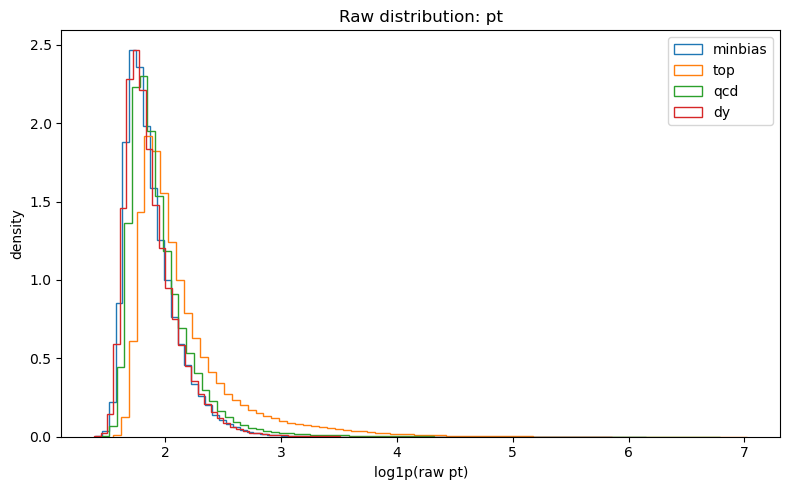

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_mha_nodes_aligned_outputs/runs/2026-07-13/collide2v_updated_dy_minbias_wide_attn_aug_top_pt_minbias100000_top100000_qcd100000_dy100000_121558/figures/raw_distribution_pt.png


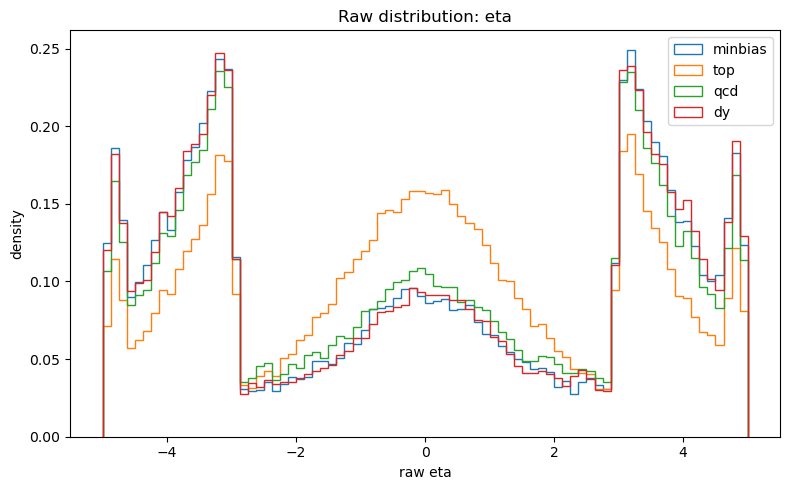

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_mha_nodes_aligned_outputs/runs/2026-07-13/collide2v_updated_dy_minbias_wide_attn_aug_top_pt_minbias100000_top100000_qcd100000_dy100000_121558/figures/raw_distribution_eta.png


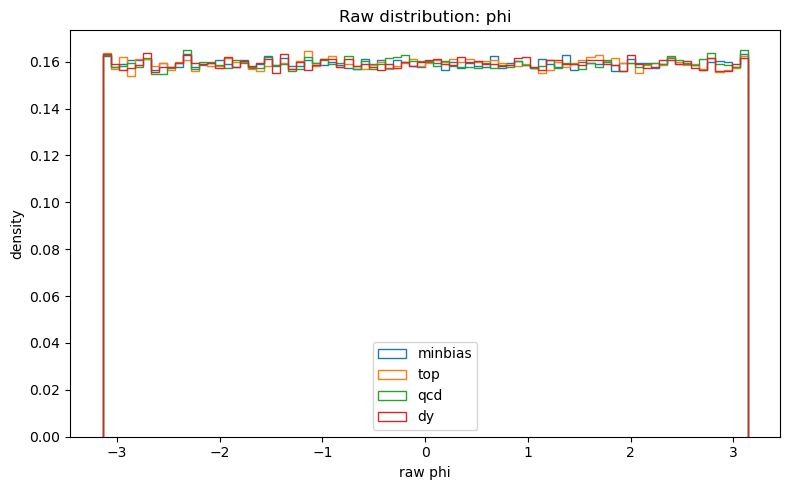

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_mha_nodes_aligned_outputs/runs/2026-07-13/collide2v_updated_dy_minbias_wide_attn_aug_top_pt_minbias100000_top100000_qcd100000_dy100000_121558/figures/raw_distribution_phi.png


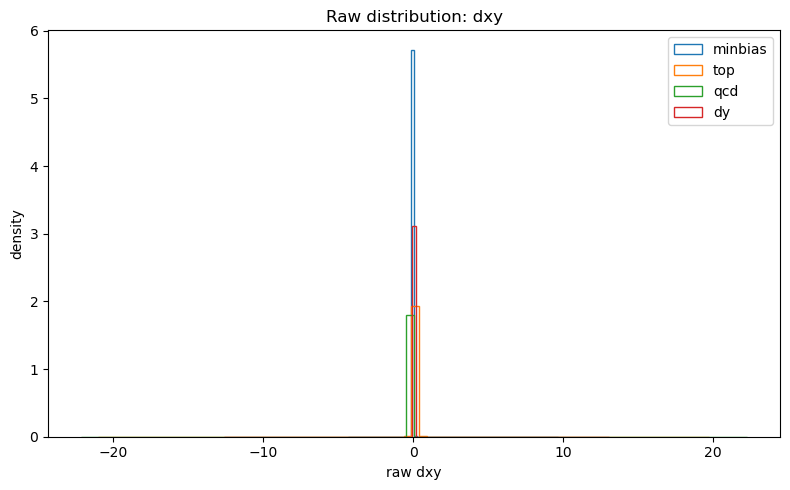

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_mha_nodes_aligned_outputs/runs/2026-07-13/collide2v_updated_dy_minbias_wide_attn_aug_top_pt_minbias100000_top100000_qcd100000_dy100000_121558/figures/raw_distribution_dxy.png


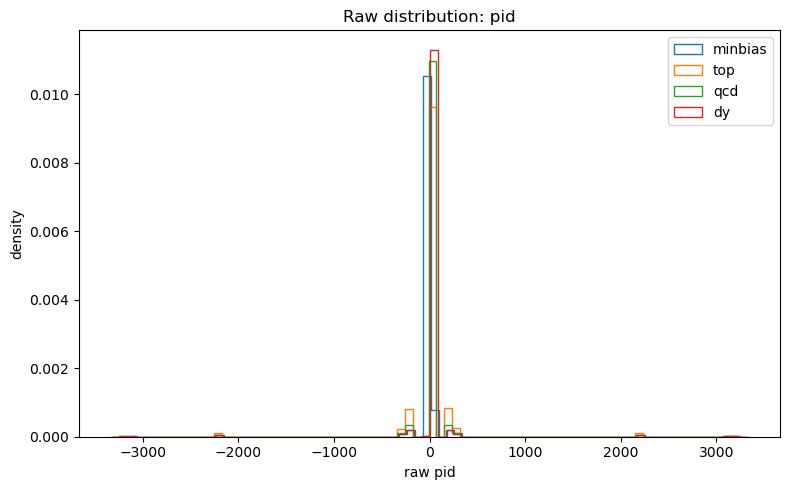

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_mha_nodes_aligned_outputs/runs/2026-07-13/collide2v_updated_dy_minbias_wide_attn_aug_top_pt_minbias100000_top100000_qcd100000_dy100000_121558/figures/raw_distribution_pid.png


In [7]:
def flatten_valid_feature(raw: np.ndarray, feature_idx: int, max_events: int = 10_000):
    arr = raw[:max_events]
    mask = arr[:, :, 0] > 0
    return arr[:, :, feature_idx][mask]

FEATURE_NAMES_RAW = ['pt', 'eta', 'phi', 'dxy', 'pid']

for feat_idx, feat_name in enumerate(FEATURE_NAMES_RAW):
    plt.figure(figsize=(8, 5))
    for cls in CLASS_NAMES:
        vals = flatten_valid_feature(raw_by_class[cls], feat_idx, RAW_SAMPLE_EVENTS_PER_CLASS)
        if feat_name == 'pt':
            vals = vals[np.isfinite(vals)]
            vals = vals[vals >= 0]
            vals = np.log1p(vals)
            xlabel = 'log1p(raw pt)'
        else:
            vals = vals[np.isfinite(vals)]
            xlabel = f'raw {feat_name}'
        if len(vals) > 0:
            plt.hist(vals, bins=80, histtype='step', density=True, label=cls)
    plt.title(f'Raw distribution: {feat_name}')
    plt.xlabel(xlabel)
    plt.ylabel('density')
    plt.legend()
    plt.tight_layout()
    out = FIGS / f'raw_distribution_{feat_name}.png'
    plt.savefig(out, dpi=150)
    plt.show()
    print('saved:', out)


## DY/MinBias input separability diagnostic

This checks whether the current L1 particle features contain an obvious DY vs MinBias discriminator before relying on the MHA latent space. It builds event-level summaries, including lepton counts and approximate opposite-sign same-flavor lepton-pair masses, then trains a small gradient-boosted binary classifier.


              precision    recall  f1-score   support

     minbias       0.54      0.80      0.65     30000
          dy       0.62      0.32      0.42     30000

    accuracy                           0.56     60000
   macro avg       0.58      0.56      0.53     60000
weighted avg       0.58      0.56      0.53     60000

Confusion matrix:
[[24068  5932]
 [20388  9612]]
DY/MinBias event-feature ROC AUC: 0.5919


,feature,auc_drop_mean,auc_drop_std
9,mean_abs_dxy,0.045099,0.001931
24,max_pt_lep,0.011328,0.000475
2,max_pt,0.008485,0.000863
23,sum_pt_lep,0.008085,0.000419
1,sum_pt,0.004634,0.000569
11,lead2_pt,0.004633,0.000939
12,lead3_pt,0.004403,0.000445
27,max_pt_gamma,0.004130,0.000716
19,n_mu,0.004128,0.000410
20,sum_pt_mu,0.003949,0.000271


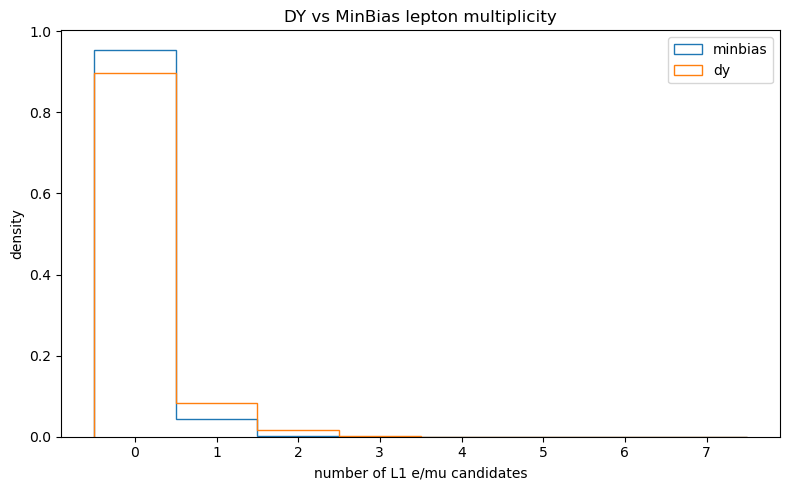

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_mha_nodes_aligned_outputs/runs/2026-07-13/collide2v_updated_dy_minbias_wide_attn_aug_top_pt_minbias100000_top100000_qcd100000_dy100000_121558/figures/dy_minbias_lepton_multiplicity.png


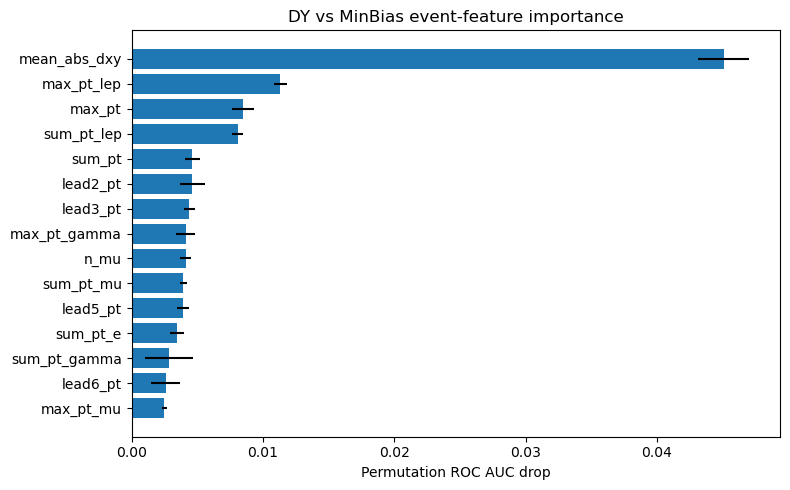

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_mha_nodes_aligned_outputs/runs/2026-07-13/collide2v_updated_dy_minbias_wide_attn_aug_top_pt_minbias100000_top100000_qcd100000_dy100000_121558/figures/dy_minbias_event_feature_importance.png
Input diagnostic: DY and MinBias are weakly separable with the current L1 features, even after adding simple lepton-pair summaries.
Prioritize attention pooling / wider latent capacity, then add stronger DY observables if DY recall remains low.


In [8]:
if RUN_DY_MINBIAS_DIAGNOSTIC:
    from sklearn.ensemble import HistGradientBoostingClassifier
    from sklearn.inspection import permutation_importance
    from sklearn.metrics import roc_auc_score

    def build_dy_minbias_event_features(raw: np.ndarray) -> pd.DataFrame:
        raw = raw[:DY_MINBIAS_DIAGNOSTIC_MAX_EVENTS]
        pt = raw[:, :, 0].astype(np.float64)
        eta = raw[:, :, 1].astype(np.float64)
        phi = raw[:, :, 2].astype(np.float64)
        dxy = raw[:, :, 3].astype(np.float64)
        pid = raw[:, :, 4].astype(np.int32)
        mask = pt > 0
        n = mask.sum(axis=1).astype(np.float64)
        safe_n = np.maximum(n, 1.0)
        pt_mask = np.where(mask, pt, 0.0)
        sorted_pt = np.sort(pt_mask, axis=1)[:, ::-1]
        features = {
            'n_constituents': n,
            'sum_pt': pt_mask.sum(axis=1),
            'max_pt': pt_mask.max(axis=1),
            'mean_pt': pt_mask.sum(axis=1) / safe_n,
            'log_sum_pt': np.log1p(pt_mask.sum(axis=1)),
            'pt_p75': np.percentile(pt_mask, 75, axis=1),
            'pt_p90': np.percentile(pt_mask, 90, axis=1),
            'pt_p95': np.percentile(pt_mask, 95, axis=1),
            'mean_abs_eta': np.where(mask, np.abs(eta), 0.0).sum(axis=1) / safe_n,
            'mean_abs_dxy': np.where(mask, np.abs(dxy), 0.0).sum(axis=1) / safe_n,
        }
        for k in range(1, 7):
            features[f'lead{k}_pt'] = sorted_pt[:, k - 1]

        pid_groups = {
            'e': [11, -11],
            'mu': [13, -13],
            'lep': [11, -11, 13, -13],
            'gamma': [22],
            'ch45': [45, -45],
            'ch65': [65, -65],
            'ch92': [92, -92],
        }
        for label, values in pid_groups.items():
            group_mask = np.isin(pid, values) & mask
            features[f'n_{label}'] = group_mask.sum(axis=1).astype(np.float64)
            features[f'sum_pt_{label}'] = np.where(group_mask, pt, 0.0).sum(axis=1)
            features[f'max_pt_{label}'] = np.where(group_mask, pt, 0.0).max(axis=1)

        max_ossf_mass = np.zeros(len(raw), dtype=np.float64)
        n_ossf_pairs = np.zeros(len(raw), dtype=np.float64)
        max_ossf_pair_sum_pt = np.zeros(len(raw), dtype=np.float64)
        lepton_pids = [11, -11, 13, -13]
        for i in range(len(raw)):
            idx = np.flatnonzero(np.isin(pid[i], lepton_pids) & mask[i])
            for a in range(len(idx)):
                ia = idx[a]
                for b in range(a + 1, len(idx)):
                    ib = idx[b]
                    if pid[i, ia] + pid[i, ib] != 0:
                        continue
                    deta = eta[i, ia] - eta[i, ib]
                    dphi = (phi[i, ia] - phi[i, ib] + np.pi) % (2 * np.pi) - np.pi
                    mass2 = 2 * pt[i, ia] * pt[i, ib] * (np.cosh(deta) - np.cos(dphi))
                    mass = np.sqrt(max(float(mass2), 0.0))
                    n_ossf_pairs[i] += 1
                    max_ossf_mass[i] = max(max_ossf_mass[i], mass)
                    max_ossf_pair_sum_pt[i] = max(max_ossf_pair_sum_pt[i], pt[i, ia] + pt[i, ib])
        features['n_ossf_lepton_pairs'] = n_ossf_pairs
        features['max_ossf_mass'] = max_ossf_mass
        features['max_ossf_pair_sum_pt'] = max_ossf_pair_sum_pt
        return pd.DataFrame(features)

    X_mb_diag = build_dy_minbias_event_features(raw_by_class['minbias'])
    X_dy_diag = build_dy_minbias_event_features(raw_by_class['dy'])
    X_diag = pd.concat([X_mb_diag, X_dy_diag], ignore_index=True)
    y_diag = np.r_[np.zeros(len(X_mb_diag), dtype=np.int64), np.ones(len(X_dy_diag), dtype=np.int64)]
    X_diag_train, X_diag_eval, y_diag_train, y_diag_eval = train_test_split(
        X_diag,
        y_diag,
        test_size=0.30,
        random_state=SEED,
        stratify=y_diag,
    )
    dy_mb_clf = HistGradientBoostingClassifier(
        max_iter=160,
        learning_rate=0.07,
        max_leaf_nodes=31,
        l2_regularization=1e-3,
        random_state=SEED,
    )
    dy_mb_clf.fit(X_diag_train, y_diag_train)
    dy_mb_proba = dy_mb_clf.predict_proba(X_diag_eval)[:, 1]
    dy_mb_pred = (dy_mb_proba >= 0.5).astype(np.int64)
    dy_mb_auc = roc_auc_score(y_diag_eval, dy_mb_proba)
    print(classification_report(y_diag_eval, dy_mb_pred, target_names=['minbias', 'dy']))
    print('Confusion matrix:')
    print(confusion_matrix(y_diag_eval, dy_mb_pred))
    print(f'DY/MinBias event-feature ROC AUC: {dy_mb_auc:.4f}')

    pd.DataFrame(classification_report(y_diag_eval, dy_mb_pred, target_names=['minbias', 'dy'], output_dict=True)).T.to_csv(
        PROJECT / 'dy_minbias_event_classifier_report.csv'
    )
    pd.DataFrame(
        confusion_matrix(y_diag_eval, dy_mb_pred),
        index=['true_minbias', 'true_dy'],
        columns=['pred_minbias', 'pred_dy'],
    ).to_csv(PROJECT / 'dy_minbias_event_classifier_confusion.csv')

    perm = permutation_importance(
        dy_mb_clf,
        X_diag_eval,
        y_diag_eval,
        n_repeats=3,
        random_state=SEED,
        n_jobs=1,
        scoring='roc_auc',
    )
    feature_importance = pd.DataFrame({
        'feature': X_diag.columns,
        'auc_drop_mean': perm.importances_mean,
        'auc_drop_std': perm.importances_std,
    }).sort_values('auc_drop_mean', ascending=False)
    feature_importance.to_csv(PROJECT / 'dy_minbias_event_feature_importance.csv', index=False)
    display(feature_importance.head(15))

    summary_blocks = []
    for cls, frame in [('minbias', X_mb_diag), ('dy', X_dy_diag)]:
        desc = frame.describe(percentiles=[0.10, 0.50, 0.90, 0.95, 0.99]).T.reset_index().rename(columns={'index': 'feature'})
        desc.insert(0, 'class', cls)
        summary_blocks.append(desc)
    pd.concat(summary_blocks, ignore_index=True).to_csv(PROJECT / 'dy_minbias_event_feature_summary.csv', index=False)

    plt.figure(figsize=(8, 5))
    for cls, frame in [('minbias', X_mb_diag), ('dy', X_dy_diag)]:
        plt.hist(frame['n_lep'], bins=np.arange(-0.5, 8.5, 1), histtype='step', density=True, label=cls)
    plt.xlabel('number of L1 e/mu candidates')
    plt.ylabel('density')
    plt.title('DY vs MinBias lepton multiplicity')
    plt.legend()
    plt.tight_layout()
    out = FIGS / 'dy_minbias_lepton_multiplicity.png'
    plt.savefig(out, dpi=150)
    plt.show()
    print('saved:', out)

    plt.figure(figsize=(8, 5))
    top_features = feature_importance.head(15).iloc[::-1]
    plt.barh(top_features['feature'], top_features['auc_drop_mean'], xerr=top_features['auc_drop_std'])
    plt.xlabel('Permutation ROC AUC drop')
    plt.title('DY vs MinBias event-feature importance')
    plt.tight_layout()
    out = FIGS / 'dy_minbias_event_feature_importance.png'
    plt.savefig(out, dpi=150)
    plt.show()
    print('saved:', out)

    if dy_mb_auc < 0.70:
        print('Input diagnostic: DY and MinBias are weakly separable with the current L1 features, even after adding simple lepton-pair summaries.')
        print('Prioritize attention pooling / wider latent capacity, then add stronger DY observables if DY recall remains low.')
else:
    print('DY/MinBias diagnostic disabled.')


## Split like `nodes.py`, then preprocess

This follows the `nodes.py` order:

1. create train/val/eval indices,
2. compute normalization constants from `raw_tensor[train_idx]`,
3. build PID mapping from `raw_tensor[train_idx]`,
4. preprocess all data with `add_pid_ohe=True`,
5. return `X_train`, `X_aug`, `X_val`, `X_eval`.

In [9]:
train_idx, val_idx, eval_idx = build_split_indices(
    y,
    class_names=CLASS_NAMES,
    label_map=LABEL_MAP,
    seed=SEED,
    balanced_val_events_per_class=BALANCED_VAL_EVENTS_PER_CLASS,
    balanced_eval_events_per_class=BALANCED_EVAL_EVENTS_PER_CLASS,
)

norm = compute_normalization_constants(raw_tensor[train_idx])
pid_mapping = build_pid_mapping(raw_tensor[train_idx])
X_all, pid_mapping = preprocess_dataset(
    raw_tensor,
    norm=norm,
    pid_mapping=pid_mapping,
    add_pid_ohe=True,
)

X_train = X_all[train_idx]
y_train = y[train_idx]
X_val = X_all[val_idx]
y_val = y[val_idx]
X_eval = X_all[eval_idx]
y_eval = y[eval_idx]

print('norm:', json.dumps(norm, indent=2))
print('pid_mapping:', pid_mapping)
print('X_all:', X_all.shape, X_all.dtype)
print('X_train:', X_train.shape, y_train.shape, pd.Series(y_train).map({v: k for k, v in LABEL_MAP.items()}).value_counts().to_dict())
print('X_val:', X_val.shape, y_val.shape, pd.Series(y_val).map({v: k for k, v in LABEL_MAP.items()}).value_counts().to_dict())
print('X_eval:', X_eval.shape, y_eval.shape, pd.Series(y_eval).map({v: k for k, v in LABEL_MAP.items()}).value_counts().to_dict())
print('n_features after PID OHE:', X_all.shape[-1])


norm: {
  "pt_min": 1.3575652837753296,
  "pt_max": 7.45587682723999,
  "eta_min": -5.0,
  "eta_max": 5.0,
  "phi_min": -3.141592653589793,
  "phi_max": 3.141592653589793,
  "dxy_min": -24.75723648071289,
  "dxy_max": 25.87984848022461
}
pid_mapping: {-3334: 0, -3312: 1, -3222: 2, -3112: 3, -2212: 4, -321: 5, -211: 6, -13: 7, -11: 8, 0: 9, 11: 10, 13: 11, 22: 12, 211: 13, 321: 14, 2212: 15, 3112: 16, 3222: 17, 3312: 18, 3334: 19}
X_all: (400000, 100, 24) float32
X_train: (280000, 100, 24) (280000,) {'dy': 70000, 'top': 70000, 'minbias': 70000, 'qcd': 70000}
X_val: (60000, 100, 24) (60000,) {'dy': 15000, 'minbias': 15000, 'qcd': 15000, 'top': 15000}
X_eval: (60000, 100, 24) (60000,) {'qcd': 15000, 'dy': 15000, 'minbias': 15000, 'top': 15000}
n_features after PID OHE: 24


## Optional simple augmentation producing `X_aug`

`nodes.py` can create `X_aug` using `GSEALAugmentation`, then preprocesses augmented raw tensors with the same `norm` and `pid_mapping`.

This notebook provides a lightweight optional augmentation: random rotation in `phi`. It preserves the same interface and preprocessing order. Keep it disabled for the first baseline.

In [10]:
if USE_AUGMENTATION:
    augmented_blocks = [X_train]
    for copy_idx in range(AUGMENTATION_COPIES):
        raw_aug_train = augment_rotate_phi(raw_tensor[train_idx])
        X_rot, _ = preprocess_dataset(raw_aug_train, norm=norm, pid_mapping=pid_mapping, add_pid_ohe=True)
        augmented_blocks.append(X_rot)
    X_aug = np.concatenate(augmented_blocks, axis=0)
    y_aug = np.tile(y_train, AUGMENTATION_COPIES + 1)
    print(f'Using phi-rotation augmentation: original + {AUGMENTATION_COPIES} rotated copies -> {X_aug.shape}')
else:
    X_aug = X_train.copy()
    y_aug = y_train.copy()
    print('Augmentation disabled. X_aug = X_train copy:', X_aug.shape)


Using phi-rotation augmentation: original + 1 rotated copies -> (560000, 100, 24)


## Plot 1D distributions after preprocessing

The first 4 features are kinematics:

```text
pt_norm, eta_norm, phi_norm, dxy
```

The remaining features are PID one-hot entries.

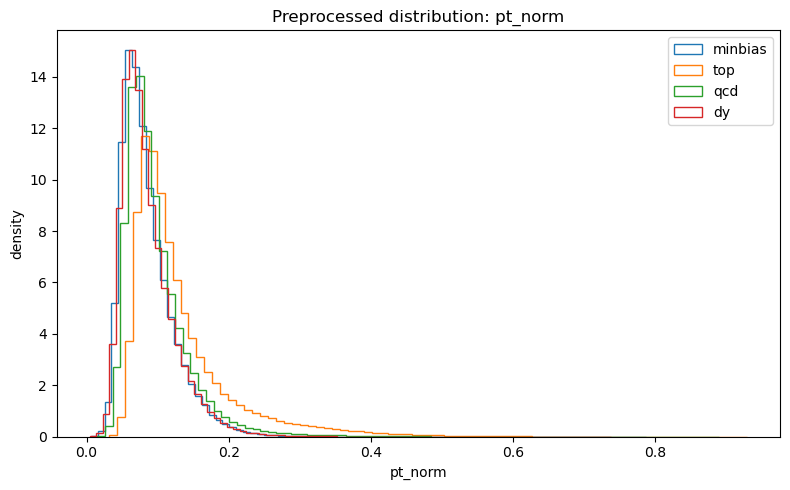

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_mha_nodes_aligned_outputs/runs/2026-07-13/collide2v_updated_dy_minbias_wide_attn_aug_top_pt_minbias100000_top100000_qcd100000_dy100000_121558/figures/preprocessed_distribution_pt_norm.png


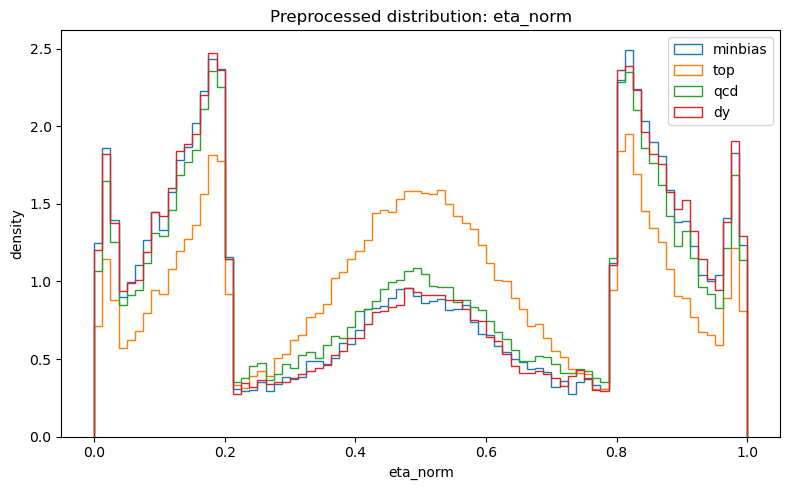

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_mha_nodes_aligned_outputs/runs/2026-07-13/collide2v_updated_dy_minbias_wide_attn_aug_top_pt_minbias100000_top100000_qcd100000_dy100000_121558/figures/preprocessed_distribution_eta_norm.png


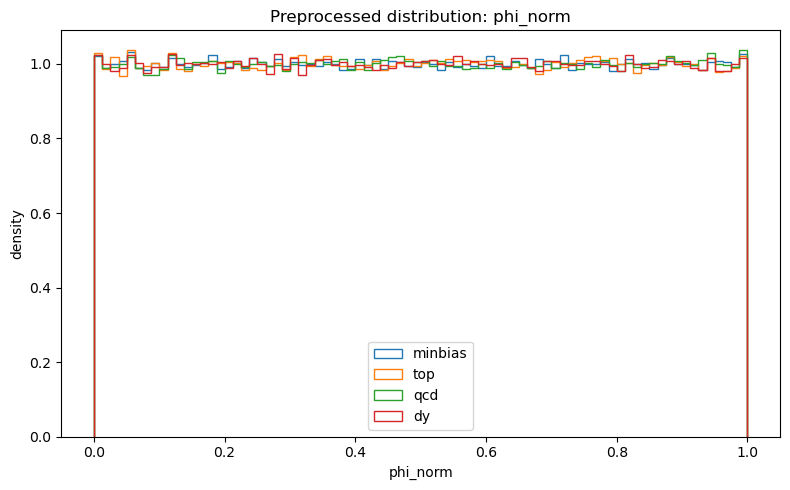

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_mha_nodes_aligned_outputs/runs/2026-07-13/collide2v_updated_dy_minbias_wide_attn_aug_top_pt_minbias100000_top100000_qcd100000_dy100000_121558/figures/preprocessed_distribution_phi_norm.png


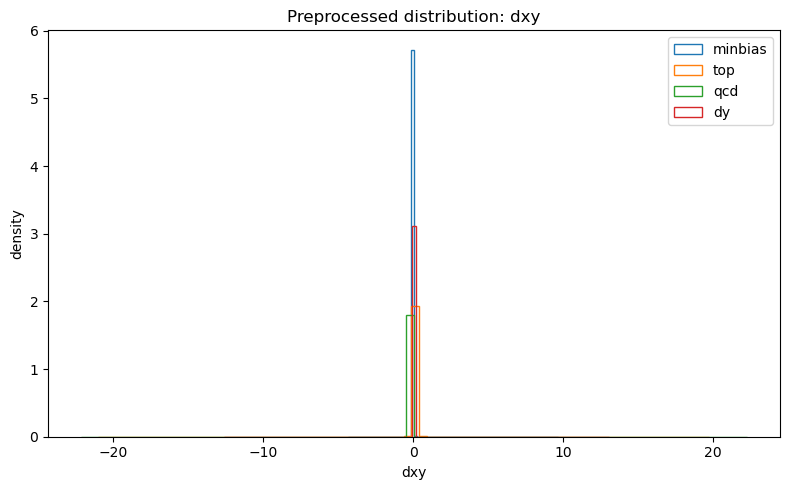

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_mha_nodes_aligned_outputs/runs/2026-07-13/collide2v_updated_dy_minbias_wide_attn_aug_top_pt_minbias100000_top100000_qcd100000_dy100000_121558/figures/preprocessed_distribution_dxy.png
PID counts: {-3334: 576, -3312: 9914, -3222: 24235, -3112: 21286, -2212: 204661, -321: 425765, -211: 1304953, -13: 23083, -11: 20055, 0: 32574858, 11: 19680, 13: 23086, 22: 3339025, 211: 1314265, 321: 431637, 2212: 207760, 3112: 23312, 3222: 22675, 3312: 8742, 3334: 432}


In [11]:
FEATURE_NAMES_PRE = ['pt_norm', 'eta_norm', 'phi_norm', 'dxy']

for feat_idx, feat_name in enumerate(FEATURE_NAMES_PRE):
    plt.figure(figsize=(8, 5))
    for cls in CLASS_NAMES:
        cls_mask = y == LABEL_MAP[cls]
        arr = X_all[cls_mask][:RAW_SAMPLE_EVENTS_PER_CLASS]
        valid = arr[:, :, 0] > 0
        vals = arr[:, :, feat_idx][valid]
        vals = vals[np.isfinite(vals)]
        if len(vals) > 0:
            plt.hist(vals, bins=80, histtype='step', density=True, label=cls)
    plt.title(f'Preprocessed distribution: {feat_name}')
    plt.xlabel(feat_name)
    plt.ylabel('density')
    plt.legend()
    plt.tight_layout()
    out = FIGS / f'preprocessed_distribution_{feat_name}.png'
    plt.savefig(out, dpi=150)
    plt.show()
    print('saved:', out)

# PID distribution after mapping
pid_counts = {}
for pid, idx in pid_mapping.items():
    pid_counts[pid] = int((raw_tensor[:, :, 4][raw_tensor[:, :, 0] > 0].astype(np.int32) == pid).sum())
print('PID counts:', pid_counts)


# Full-precision PyTorch standard MHA model

This is the dense PyTorch analogue of `linformer.py`, with the Linformer low-rank sequence projection replaced by standard (full) multi-head self-attention:

| Original HGQ/Keras layer | PyTorch full precision equivalent |
|---|---|
| `QDense` | `nn.Linear` |
| `QAdd` | `+` residual add |
| `QSum(axes=1) / N` | `sum(dim=1) / N` |
| `QLinformerAttention` | dense PyTorch standard multi-head attention (no low-rank sequence projection) |
| softmax output | logits + `CrossEntropyLoss` |

In [12]:
from mha_model import StandardMHA, MHAEmbeddingFullPrecision

model = MHAEmbeddingFullPrecision(
    n_constituents=N_CONSTITUENTS,
    n_features=X_train.shape[-1],
    latent_dim=LATENT_DIM,
    n_classes=N_CLASSES,
    ff_dim=FF_DIM,
    num_heads=NUM_HEADS,
    pooling_mode=POOLING_MODE,
).to(DEVICE)

n_params = sum(p.numel() for p in model.parameters())
print(model)
print('parameters:', n_params)


MHAEmbeddingFullPrecision(
  (input_proj): Linear(in_features=24, out_features=64, bias=True)
  (attention1): StandardMHA(
    (q_proj): Linear(in_features=64, out_features=64, bias=True)
    (k_proj): Linear(in_features=64, out_features=64, bias=True)
    (v_proj): Linear(in_features=64, out_features=64, bias=True)
    (out_proj): Linear(in_features=64, out_features=64, bias=True)
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (attention2): StandardMHA(
    (q_proj): Linear(in_features=64, out_features=64, bias=True)
    (k_proj): Linear(in_features=64, out_features=64, bias=True)
    (v_proj): Linear(in_features=64, out_features=64, bias=True)
    (out_proj): Linear(in_features=64, out_features=64, bias=True)
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (pool_score): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
  (post_pool): Sequential(
    (0): Linear(in_features=64, 

## Training

This trains the classifier head using `CrossEntropyLoss` and uses the `latent` output as the embedding space. The model remains full precision.

In [13]:
class TensorDatasetTorch(Dataset):
    def __init__(self, X: np.ndarray, y: np.ndarray):
        self.X = torch.from_numpy(X.astype(np.float32, copy=False))
        self.y = torch.from_numpy(y.astype(np.int64, copy=False))
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

def make_class_weights(y_labels: np.ndarray):
    if CLASS_WEIGHT_MODE == 'none':
        return None
    if CLASS_WEIGHT_MODE != 'balanced':
        raise ValueError(f'Unknown CLASS_WEIGHT_MODE={CLASS_WEIGHT_MODE!r}')
    counts = np.bincount(y_labels, minlength=N_CLASSES).astype(np.float64)
    weights = len(y_labels) / (N_CLASSES * np.maximum(counts, 1.0))
    return torch.tensor(weights, dtype=torch.float32, device=DEVICE)

CLASS_WEIGHTS_TENSOR = make_class_weights(y_aug)
print('CLASS_WEIGHTS_TENSOR:', None if CLASS_WEIGHTS_TENSOR is None else CLASS_WEIGHTS_TENSOR.detach().cpu().numpy())

train_loader = DataLoader(
    TensorDatasetTorch(X_aug, y_aug),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)
val_loader = DataLoader(
    TensorDatasetTorch(X_val, y_val),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

def run_epoch(model, loader, optimizer=None):
    is_train = optimizer is not None
    model.train(is_train)
    total_loss = 0.0
    total_correct = 0
    total = 0

    for xb, yb in loader:
        xb = xb.to(DEVICE, non_blocking=True)
        yb = yb.to(DEVICE, non_blocking=True)

        with torch.set_grad_enabled(is_train):
            out = model(xb)
            loss = F.cross_entropy(out['logits'], yb, weight=CLASS_WEIGHTS_TENSOR)
            if is_train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()

        total_loss += float(loss.item()) * len(xb)
        pred = out['logits'].argmax(dim=1)
        total_correct += int((pred == yb).sum().item())
        total += len(xb)

    return total_loss / max(total, 1), total_correct / max(total, 1)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
best_val_loss = float('inf')
history = []

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    train_loss, train_acc = run_epoch(model, train_loader, optimizer)
    val_loss, val_acc = run_epoch(model, val_loader, optimizer=None)
    elapsed = time.time() - t0

    row = {
        'epoch': epoch,
        'train_loss': train_loss,
        'train_acc': train_acc,
        'val_loss': val_loss,
        'val_acc': val_acc,
        'elapsed_s': elapsed,
    }
    history.append(row)
    print(
        f"Epoch {epoch:03d}/{EPOCHS} | "
        f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
        f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} | {elapsed:.1f}s"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save({
            'model_state_dict': model.state_dict(),
            'config': {
                'experiment_preset': EXPERIMENT_PRESET,
                'events_per_class': EVENTS_PER_CLASS,
                'balanced_val_events_per_class': BALANCED_VAL_EVENTS_PER_CLASS,
                'balanced_eval_events_per_class': BALANCED_EVAL_EVENTS_PER_CLASS,
                'feature_mode': FEATURE_MODE,
                'class_weight_mode': CLASS_WEIGHT_MODE,
                'class_weights': None if CLASS_WEIGHTS_TENSOR is None else CLASS_WEIGHTS_TENSOR.detach().cpu().numpy().tolist(),
                'n_constituents': N_CONSTITUENTS,
                'n_features': X_train.shape[-1],
                'latent_dim': LATENT_DIM,
                'n_classes': N_CLASSES,
                'ff_dim': FF_DIM,
                'num_heads': NUM_HEADS,
                'pooling_mode': POOLING_MODE,
                'use_augmentation': USE_AUGMENTATION,
                'augmentation_copies': AUGMENTATION_COPIES,
                'pid_mapping': pid_mapping,
                'norm': norm,
                'class_names': CLASS_NAMES,
            },
        }, MODELS / 'mha_nodes_aligned_best.pt')

pd.DataFrame(history).to_csv(PROJECT / 'training_history.csv', index=False)
print('saved model:', MODELS / 'mha_nodes_aligned_best.pt')


# Reload the best (not necessarily last-epoch) weights, then export an eval-ready
# full-module checkpoint: eval_quality.py expects torch.load(path) to return a
# callable nn.Module directly, not a {state_dict, config} checkpoint dict.
best_ckpt = torch.load(MODELS / 'mha_nodes_aligned_best.pt', map_location=DEVICE)
model.load_state_dict(best_ckpt['model_state_dict'])
model.eval()

from mha_model import LatentOnlyWrapper

torch.save(LatentOnlyWrapper(model), MODELS / 'mha_nodes_aligned_best_for_eval.pt')
print('saved eval-ready model:', MODELS / 'mha_nodes_aligned_best_for_eval.pt')


CLASS_WEIGHTS_TENSOR: None
Epoch 001/30 | train_loss=0.8947 train_acc=0.5431 | val_loss=0.8546 val_acc=0.5636 | 149.1s
Epoch 002/30 | train_loss=0.8442 train_acc=0.5645 | val_loss=0.8174 val_acc=0.5714 | 159.2s
Epoch 003/30 | train_loss=0.8178 train_acc=0.5814 | val_loss=0.8028 val_acc=0.5881 | 157.4s
Epoch 004/30 | train_loss=0.8088 train_acc=0.5850 | val_loss=0.8012 val_acc=0.5900 | 158.7s
Epoch 005/30 | train_loss=0.8030 train_acc=0.5874 | val_loss=0.7989 val_acc=0.5886 | 154.9s
Epoch 006/30 | train_loss=0.7986 train_acc=0.5895 | val_loss=0.8043 val_acc=0.5891 | 156.4s
Epoch 007/30 | train_loss=0.7954 train_acc=0.5914 | val_loss=0.7915 val_acc=0.5934 | 160.1s
Epoch 008/30 | train_loss=0.7928 train_acc=0.5922 | val_loss=0.7985 val_acc=0.5887 | 152.9s
Epoch 009/30 | train_loss=0.7887 train_acc=0.5948 | val_loss=0.7876 val_acc=0.5966 | 155.8s
Epoch 010/30 | train_loss=0.7873 train_acc=0.5957 | val_loss=0.7823 val_acc=0.5976 | 155.4s
Epoch 011/30 | train_loss=0.7847 train_acc=0.5975 | v

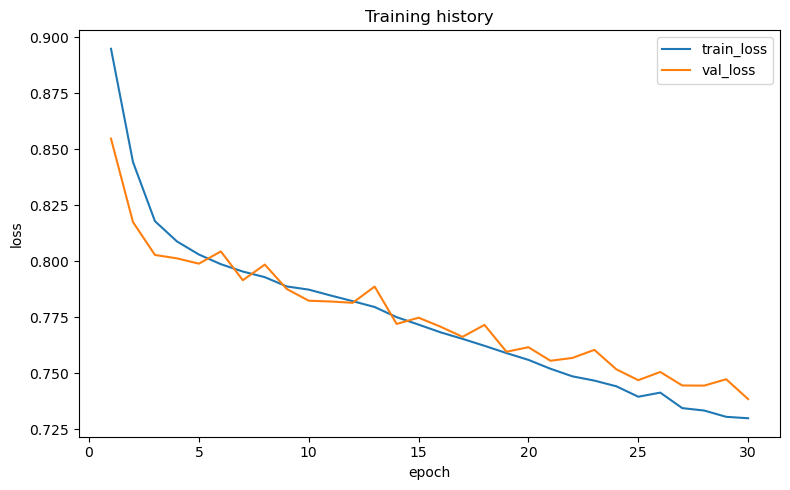

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_mha_nodes_aligned_outputs/runs/2026-07-13/collide2v_updated_dy_minbias_wide_attn_aug_top_pt_minbias100000_top100000_qcd100000_dy100000_121558/figures/training_loss.png


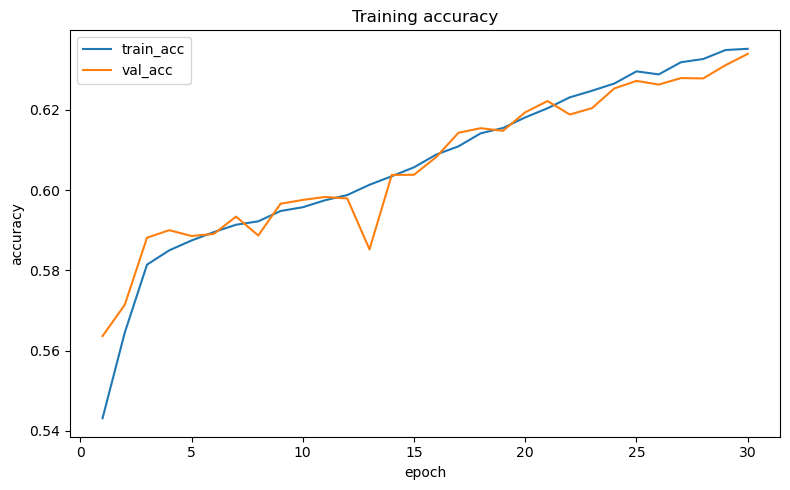

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_mha_nodes_aligned_outputs/runs/2026-07-13/collide2v_updated_dy_minbias_wide_attn_aug_top_pt_minbias100000_top100000_qcd100000_dy100000_121558/figures/training_accuracy.png


In [14]:
hist = pd.DataFrame(history)
plt.figure(figsize=(8, 5))
plt.plot(hist['epoch'], hist['train_loss'], label='train_loss')
plt.plot(hist['epoch'], hist['val_loss'], label='val_loss')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.title('Training history')
plt.legend()
plt.tight_layout()
out = FIGS / 'training_loss.png'
plt.savefig(out, dpi=150)
plt.show()
print('saved:', out)

plt.figure(figsize=(8, 5))
plt.plot(hist['epoch'], hist['train_acc'], label='train_acc')
plt.plot(hist['epoch'], hist['val_acc'], label='val_acc')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.title('Training accuracy')
plt.legend()
plt.tight_layout()
out = FIGS / 'training_accuracy.png'
plt.savefig(out, dpi=150)
plt.show()
print('saved:', out)


## Evaluation and embeddings

In [15]:
# Load best checkpoint
ckpt = torch.load(MODELS / 'mha_nodes_aligned_best.pt', map_location=DEVICE)
model.load_state_dict(ckpt['model_state_dict'])
model.eval()

def predict_latents_logits(model, X: np.ndarray, batch_size: int = 2048):
    loader = DataLoader(
        TensorDatasetTorch(X, np.zeros(len(X), dtype=np.int64)),
        batch_size=batch_size,
        shuffle=False,
        num_workers=NUM_WORKERS,
    )
    latents = []
    logits = []
    with torch.no_grad():
        for xb, _ in loader:
            xb = xb.to(DEVICE)
            out = model(xb)
            latents.append(out['latent'].cpu().numpy())
            logits.append(out['logits'].cpu().numpy())
    return np.concatenate(latents, axis=0), np.concatenate(logits, axis=0)

Z_eval, logits_eval = predict_latents_logits(model, X_eval)
pred_eval = logits_eval.argmax(axis=1)
report_text = classification_report(y_eval, pred_eval, target_names=CLASS_NAMES)
report_dict = classification_report(y_eval, pred_eval, target_names=CLASS_NAMES, output_dict=True)
cm_eval = confusion_matrix(y_eval, pred_eval)
print(report_text)
print('Confusion matrix:')
print(cm_eval)

dy_idx = LABEL_MAP['dy']
minbias_idx = LABEL_MAP['minbias']
dy_total = cm_eval[dy_idx].sum()
dy_to_minbias = cm_eval[dy_idx, minbias_idx]
print(f'DY -> MinBias confusion: {dy_to_minbias:,}/{dy_total:,} ({dy_to_minbias / max(dy_total, 1):.1%})')

pd.DataFrame(report_dict).T.to_csv(PROJECT / 'classification_report_eval.csv')
pd.DataFrame(cm_eval, index=[f'true_{c}' for c in CLASS_NAMES], columns=[f'pred_{c}' for c in CLASS_NAMES]).to_csv(PROJECT / 'confusion_matrix_eval.csv')
np.save(PROJECT / 'eval_latents.npy', Z_eval)
np.save(PROJECT / 'eval_logits.npy', logits_eval)


              precision    recall  f1-score   support

     minbias       0.47      0.65      0.55     15000
         top       0.92      0.94      0.93     15000
         qcd       0.64      0.55      0.59     15000
          dy       0.52      0.38      0.44     15000

    accuracy                           0.63     60000
   macro avg       0.64      0.63      0.63     60000
weighted avg       0.64      0.63      0.63     60000

Confusion matrix:
[[ 9801     6  1861  3332]
 [    8 14059   902    31]
 [ 3693  1078  8237  1992]
 [ 7269    66  1929  5736]]
DY -> MinBias confusion: 7,269/15,000 (48.5%)


In [16]:
# DY final-state diagnostic using gen-level information for labels only.
# Model inputs remain strictly L1-only. These labels are used only for post-training analysis.
RUN_DY_FINAL_STATE_DIAGNOSTIC = bool(int(os.environ.get('RUN_DY_FINAL_STATE_DIAGNOSTIC', '1')))
DY_FINAL_STATE_LABELS = ['ee', 'mumu', 'tautau', 'other']
DY_FINAL_STATE_NAME = {
    'ee': 'DY->ee',
    'mumu': 'DY->mumu',
    'tautau': 'DY->tautau',
    'other': 'DY->other/ambiguous',
}


GEN_PID_BRANCH_CANDIDATES = [
    'FullReco_GenPart_PID',
    'GenPart_pdgId',
    'GenPart_PID',
    'GenPart_pdgid',
]
GEN_STATUS_BRANCH_CANDIDATES = [
    'FullReco_GenPart_Status',
    'GenPart_status',
    'GenPart_Status',
]


def infer_dy_final_state_from_gen(pid, status):
    pid = np.asarray(pid, dtype=np.int32)
    status = np.asarray(status, dtype=np.int32)
    abs_pid = np.abs(pid)

    hard_mask = (status == 23) & np.isin(abs_pid, [11, 13, 15])
    hard = abs_pid[hard_mask]
    counts = {flav: int(np.sum(hard == flav)) for flav in [11, 13, 15]}
    for flav, label in [(11, 'ee'), (13, 'mumu'), (15, 'tautau')]:
        if counts[flav] >= 2:
            return label

    # Fallback: use all gen leptons only if the hard-process pair is not available.
    all_leptons = abs_pid[np.isin(abs_pid, [11, 13, 15])]
    counts_all = {flav: int(np.sum(all_leptons == flav)) for flav in [11, 13, 15]}
    for flav, label in [(15, 'tautau'), (13, 'mumu'), (11, 'ee')]:
        if counts_all[flav] >= 2:
            return label
    return 'other'



def select_first_available_branch(available_columns, candidates):
    available = set(available_columns)
    return next((candidate for candidate in candidates if candidate in available), None)


def stream_dy_final_states_from_samples_json(target_events: int) -> Optional[np.ndarray]:
    import uproot
    import awkward as ak

    cache_path = CACHE / f'dy_gen_final_states_{target_events}_samplesjson.npy'
    if cache_path.exists():
        log(f'DY final-state labels: loading cache {cache_path}')
        return np.load(cache_path, allow_pickle=True)

    labels = []
    root_files = root_files_for_class('dy')
    log(f'DY final-state labels: DATA_SOURCE=samples_json, files={root_files}')

    for root_file in root_files:
        if len(labels) >= target_events:
            break
        with uproot.open(root_file) as fh:
            tree = fh[ROOT_TREE_NAME]
            available_columns = list(tree.keys())
            pid_branch = select_first_available_branch(available_columns, GEN_PID_BRANCH_CANDIDATES)
            status_branch = select_first_available_branch(available_columns, GEN_STATUS_BRANCH_CANDIDATES)
            if pid_branch is None or status_branch is None:
                log(
                    'DY final-state labels: gen-level branches not found in ROOT file. '
                    f'pid_branch={pid_branch}, status_branch={status_branch}, available sample={available_columns[:80]}'
                )
                return None
            columns = [pid_branch, status_branch]
            log(f'DY final-state labels: selected ROOT gen branches pid={pid_branch}, status={status_branch}')

        read_batch_size = int(globals().get('RAW_READ_BATCH_SIZE', 512))
        for batch in uproot.iterate(
            [f'{root_file}:{ROOT_TREE_NAME}'],
            expressions=columns,
            step_size=read_batch_size,
            library='ak',
        ):
            n_rows = len(batch[pid_branch])
            for row_idx in range(n_rows):
                label = infer_dy_final_state_from_gen(
                    ak.to_numpy(batch[pid_branch][row_idx]),
                    ak.to_numpy(batch[status_branch][row_idx]),
                )
                labels.append(label)
                if len(labels) >= target_events:
                    break
            if len(labels) >= target_events:
                break
        log(f'DY final-state labels: loaded {len(labels):,}/{target_events:,}')

    if len(labels) < target_events:
        raise RuntimeError(f'DY final-state labels: loaded only {len(labels):,}/{target_events:,}')

    labels = np.asarray(labels[:target_events], dtype=object)
    np.save(cache_path, labels, allow_pickle=True)
    log(f'DY final-state labels: saved cache {cache_path}')
    return labels


def stream_dy_final_states(target_events: int) -> Optional[np.ndarray]:
    if DATA_SOURCE == 'samples_json':
        return stream_dy_final_states_from_samples_json(target_events)
    if DATA_SOURCE == 'hf':
        return stream_dy_final_states_from_hf(target_events)
    if DATA_SOURCE == 'collide2v_updated':
        log('DY final-state diagnostic skipped for updated Collide-2V because gen-level labels are not guaranteed in this source.')
        return None
    raise ValueError("DATA_SOURCE must be 'collide2v_updated', 'samples_json', or 'hf'")

def stream_dy_final_states_from_hf(target_events: int) -> np.ndarray:
    import pyarrow as pa
    import pyarrow.parquet as pq
    from huggingface_hub import HfFileSystem

    cache_path = CACHE / f'dy_gen_final_states_{target_events}.npy'
    if cache_path.exists():
        log(f'DY final-state labels: loading cache {cache_path}')
        return np.load(cache_path, allow_pickle=True)

    fs = HfFileSystem()
    labels = []
    columns = ['FullReco_GenPart_PID', 'FullReco_GenPart_Status']
    files = list_hf_parquet_files(DATASET_ID, HF_SAMPLES['dy'][0])
    log(f'DY final-state labels: reading gen-level columns from {len(files):,} parquet files')

    for rel in files:
        if len(labels) >= target_events:
            break
        path = f'hf://datasets/{DATASET_ID}/{rel}'
        with fs.open(path, 'rb') as fh:
            pq_file = pq.ParquetFile(fh)
            available_columns = set(pq_file.schema_arrow.names)
            missing = [col for col in columns if col not in available_columns]
            if missing:
                raise RuntimeError(f'Missing gen-level columns in {rel}: {missing}')
            read_batch_size = int(globals().get('RAW_READ_BATCH_SIZE', 512))
            for batch in pq_file.iter_batches(columns=columns, batch_size=read_batch_size):
                table = pa.Table.from_batches([batch])
                data = table.to_pydict()
                for row_idx in range(table.num_rows):
                    label = infer_dy_final_state_from_gen(
                        data['FullReco_GenPart_PID'][row_idx],
                        data['FullReco_GenPart_Status'][row_idx],
                    )
                    labels.append(label)
                    if len(labels) >= target_events:
                        break
                if len(labels) >= target_events:
                    break
        log(f'DY final-state labels: loaded {len(labels):,}/{target_events:,}')

    if len(labels) < target_events:
        raise RuntimeError(f'DY final-state labels: loaded only {len(labels):,}/{target_events:,}')

    labels = np.asarray(labels[:target_events], dtype=object)
    np.save(cache_path, labels, allow_pickle=True)
    log(f'DY final-state labels: saved cache {cache_path}')
    return labels


if RUN_DY_FINAL_STATE_DIAGNOSTIC:
    dy_target_events = EVENTS_PER_CLASS['dy']
    dy_final_state_by_event = stream_dy_final_states(dy_target_events)
    if dy_final_state_by_event is None:
        log('DY final-state diagnostic skipped because gen-level branches were not available for the selected DATA_SOURCE.')
        RUN_DY_FINAL_STATE_DIAGNOSTIC = False
    else:
        print('DY final-state counts loaded:', pd.Series(dy_final_state_by_event).value_counts().to_dict())

        dy_final_state_all = np.full(len(y), 'non_dy', dtype=object)
        dy_global_idx = np.flatnonzero(y == LABEL_MAP['dy'])
        if len(dy_global_idx) != len(dy_final_state_by_event):
            raise RuntimeError(
                f'DY label alignment mismatch: global DY events={len(dy_global_idx):,}, '
                f'final-state labels={len(dy_final_state_by_event):,}'
            )
        dy_final_state_all[dy_global_idx] = dy_final_state_by_event

        eval_true_class = np.asarray([CLASS_NAMES[i] for i in y_eval], dtype=object)
        eval_pred_class = np.asarray([CLASS_NAMES[i] for i in pred_eval], dtype=object)
        eval_dy_final_state = dy_final_state_all[eval_idx]

        dy_eval_mask = y_eval == LABEL_MAP['dy']
        dy_eval = pd.DataFrame({
            'dy_final_state': eval_dy_final_state[dy_eval_mask],
            'pred_class': eval_pred_class[dy_eval_mask],
        })

        dy_final_state_counts = pd.Series(dy_final_state_by_event, name='count').value_counts().rename_axis('dy_final_state').reset_index(name='n_loaded')
        dy_final_state_counts.to_csv(PROJECT / 'dy_final_state_counts.csv', index=False)

        dy_final_state_confusion = pd.crosstab(dy_eval['dy_final_state'], dy_eval['pred_class'])
        for class_name in CLASS_NAMES:
            if class_name not in dy_final_state_confusion.columns:
                dy_final_state_confusion[class_name] = 0
        dy_final_state_confusion = dy_final_state_confusion[CLASS_NAMES]
        dy_final_state_confusion.to_csv(PROJECT / 'dy_final_state_eval_confusion.csv')

        dy_rows = []
        for label in DY_FINAL_STATE_LABELS:
            sub = dy_eval[dy_eval['dy_final_state'] == label]
            n = len(sub)
            if n == 0:
                dy_rows.append({
                    'dy_final_state': label,
                    'display_name': DY_FINAL_STATE_NAME[label],
                    'support': 0,
                    'recall_as_dy': np.nan,
                    'confusion_to_minbias': np.nan,
                    'confusion_to_qcd': np.nan,
                    'confusion_to_top': np.nan,
                })
                continue
            counts = sub['pred_class'].value_counts()
            dy_rows.append({
                'dy_final_state': label,
                'display_name': DY_FINAL_STATE_NAME[label],
                'support': n,
                'recall_as_dy': float(counts.get('dy', 0) / n),
                'confusion_to_minbias': float(counts.get('minbias', 0) / n),
                'confusion_to_qcd': float(counts.get('qcd', 0) / n),
                'confusion_to_top': float(counts.get('top', 0) / n),
            })
        dy_final_state_report = pd.DataFrame(dy_rows)
        dy_final_state_report.to_csv(PROJECT / 'dy_final_state_eval_report.csv', index=False)
        print('DY final-state evaluation report:')
        display(dy_final_state_report)
        print('DY final-state confusion:')
        display(dy_final_state_confusion)

        # Latent-space diagnostic: all background classes plus DY split by gen final state.
        latent_groups = eval_true_class.copy()
        for label in DY_FINAL_STATE_LABELS:
            mask = dy_eval_mask & (eval_dy_final_state == label)
            latent_groups[mask] = DY_FINAL_STATE_NAME[label]

        from sklearn.decomposition import PCA
        pca_sub = PCA(n_components=2, random_state=SEED)
        Z_eval_pca_sub = pca_sub.fit_transform(Z_eval)

        rng = np.random.default_rng(SEED)
        plot_groups = ['minbias', 'top', 'qcd'] + [DY_FINAL_STATE_NAME[label] for label in DY_FINAL_STATE_LABELS]
        max_points_per_group = int(os.environ.get('DY_FINAL_STATE_PCA_MAX_POINTS_PER_GROUP', '3000'))
        plt.figure(figsize=(9, 7))
        for group in plot_groups:
            idx = np.flatnonzero(latent_groups == group)
            if len(idx) == 0:
                continue
            if len(idx) > max_points_per_group:
                idx = rng.choice(idx, size=max_points_per_group, replace=False)
            plt.scatter(Z_eval_pca_sub[idx, 0], Z_eval_pca_sub[idx, 1], s=6, alpha=0.35, label=f'{group} (n={len(idx)})')
        plt.xlabel('PCA 1')
        plt.ylabel('PCA 2')
        plt.title('Eval latent PCA with DY gen-level final states')
        plt.legend(markerscale=2, fontsize=8)
        plt.tight_layout()
        out = FIGS / 'embedding_pca_eval_dy_final_states.png'
        plt.savefig(out, dpi=160)
        plt.show()
        print('saved:', out)

        # Simple centroid-distance summary in latent space for separation monitoring.
        centroid_rows = []
        centroids = {}
        for group in plot_groups:
            idx = np.flatnonzero(latent_groups == group)
            if len(idx) == 0:
                continue
            centroids[group] = Z_eval[idx].mean(axis=0)
        group_names = sorted(centroids)
        for i, g1 in enumerate(group_names):
            for g2 in group_names[i + 1:]:
                centroid_rows.append({
                    'group_a': g1,
                    'group_b': g2,
                    'latent_centroid_distance': float(np.linalg.norm(centroids[g1] - centroids[g2])),
                })
        centroid_df = pd.DataFrame(centroid_rows).sort_values('latent_centroid_distance')
        centroid_df.to_csv(PROJECT / 'latent_centroid_distances_eval_dy_final_states.csv', index=False)
        print('Closest latent centroids:')
        display(centroid_df.head(15))
else:
        print('RUN_DY_FINAL_STATE_DIAGNOSTIC is disabled.')


[13:42:16] DY final-state diagnostic skipped for updated Collide-2V because gen-level labels are not guaranteed in this source.
[13:42:16] DY final-state diagnostic skipped because gen-level branches were not available for the selected DATA_SOURCE.


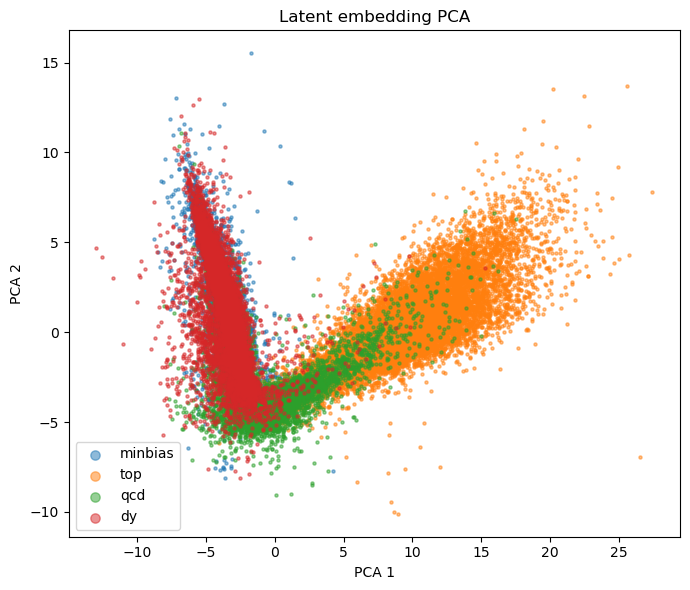

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_mha_nodes_aligned_outputs/runs/2026-07-13/collide2v_updated_dy_minbias_wide_attn_aug_top_pt_minbias100000_top100000_qcd100000_dy100000_121558/figures/embedding_pca_eval.png


In [17]:
pca2 = PCA(n_components=2, random_state=SEED)
Z2 = pca2.fit_transform(Z_eval)

plt.figure(figsize=(7, 6))
for cls in CLASS_NAMES:
    m = y_eval == LABEL_MAP[cls]
    plt.scatter(Z2[m, 0], Z2[m, 1], s=5, alpha=0.5, label=cls)
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.title('Latent embedding PCA')
plt.legend(markerscale=3)
plt.tight_layout()
out = FIGS / 'embedding_pca_eval.png'
plt.savefig(out, dpi=150)
plt.show()
print('saved:', out)


## Mahalanobis anomaly score

This follows the repository anomaly-score idea:

1. extract model latents,
2. fit PCA on normal-class latents,
3. fit empirical covariance in PCA space,
4. anomaly score = negative Gaussian log-probability, equivalent to a Mahalanobis-distance score plus normalization constants.

Here `MinBias` is the normal class by default.

In [18]:
# Fit on normal-class train latents only.
normal_train_mask = y_train == NORMAL_CLASS_IDX
Z_train_normal, _ = predict_latents_logits(model, X_train[normal_train_mask])

PCA_DIM = min(16, Z_train_normal.shape[1])
pca_maha = PCA(n_components=PCA_DIM, whiten=False, random_state=SEED)
Z_normal_pca = pca_maha.fit_transform(Z_train_normal)

cov = EmpiricalCovariance().fit(Z_normal_pca)
mu = cov.location_
Sigma = cov.covariance_ + 1e-6 * np.eye(PCA_DIM)
Sigma_inv = np.linalg.inv(Sigma)
sign, logdet = np.linalg.slogdet(Sigma)
D = PCA_DIM

def mahalanobis_negative_logprob(latents: np.ndarray) -> np.ndarray:
    Zp = pca_maha.transform(latents)
    diff = Zp - mu
    d2 = np.einsum('bi,ij,bj->b', diff, Sigma_inv, diff)
    log_prob = -0.5 * (d2 + logdet + D * np.log(2 * np.pi))
    return -log_prob.astype(np.float32)

maha_scores_eval = mahalanobis_negative_logprob(Z_eval)
np.save(PROJECT / 'mahalanobis_scores_eval.npy', maha_scores_eval)

summary = []
for cls in CLASS_NAMES:
    scores = maha_scores_eval[y_eval == LABEL_MAP[cls]]
    summary.append({
        'class': cls,
        'n': len(scores),
        'mean_score': float(np.mean(scores)),
        'std_score': float(np.std(scores)),
        'p50': float(np.percentile(scores, 50)),
        'p90': float(np.percentile(scores, 90)),
        'p95': float(np.percentile(scores, 95)),
        'p99': float(np.percentile(scores, 99)),
        'p99_5': float(np.percentile(scores, 99.5)),
        'p99_9': float(np.percentile(scores, 99.9)),
    })
summary_df = pd.DataFrame(summary)
summary_df.to_csv(PROJECT / 'mahalanobis_summary_eval.csv', index=False)
display(summary_df)


,class,n,mean_score,std_score,p50,p90,p95,p99,p99_5,p99_9
0,minbias,15000,8.157479,34.755840,1.884360,12.717002,27.364270,118.579693,210.047038,517.279413
1,top,15000,1257.268799,1033.390381,1023.897522,2586.244653,3204.478687,4739.500942,5451.499023,6858.634290
2,qcd,15000,74.469948,222.270508,5.578435,192.743440,372.516722,1047.074133,1369.566089,2386.867351
3,dy,15000,33.272072,143.483902,2.171991,48.555073,156.508293,709.412864,1111.964827,1713.770095


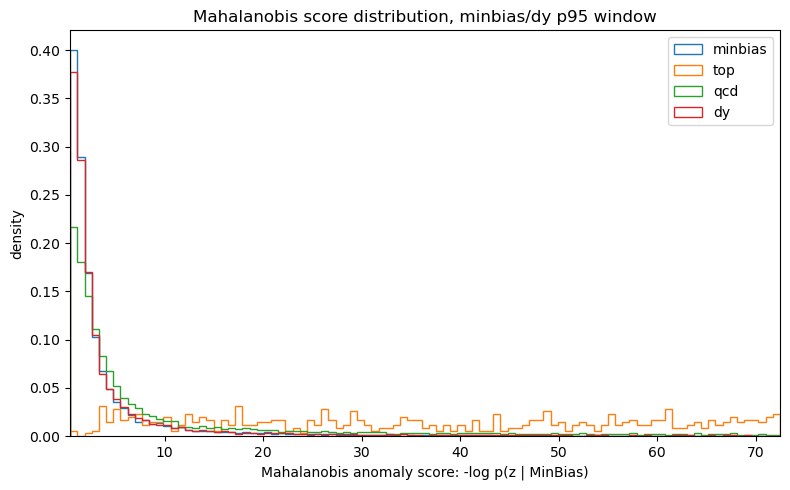

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_mha_nodes_aligned_outputs/runs/2026-07-13/collide2v_updated_dy_minbias_wide_attn_aug_top_pt_minbias100000_top100000_qcd100000_dy100000_121558/figures/mahalanobis_scores_eval.png


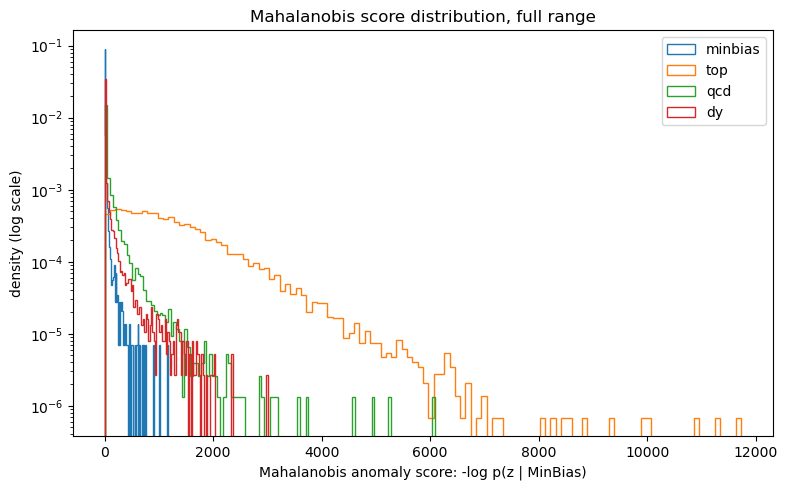

saved: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_mha_nodes_aligned_outputs/runs/2026-07-13/collide2v_updated_dy_minbias_wide_attn_aug_top_pt_minbias100000_top100000_qcd100000_dy100000_121558/figures/mahalanobis_scores_eval_logy_full_range.png


In [19]:
MAHA_FOCUS_CLASSES = ['minbias', 'dy']
MAHA_FOCUS_PERCENTILE = 95.0
focus_scores = np.concatenate([
    maha_scores_eval[y_eval == LABEL_MAP[cls]]
    for cls in MAHA_FOCUS_CLASSES
])
focus_scores = focus_scores[np.isfinite(focus_scores)]
clip_lo = float(np.percentile(focus_scores, 0.5))
clip_hi = float(np.percentile(focus_scores, MAHA_FOCUS_PERCENTILE))
bins = np.linspace(clip_lo, clip_hi, 100)

plt.figure(figsize=(8, 5))
for cls in CLASS_NAMES:
    scores = maha_scores_eval[y_eval == LABEL_MAP[cls]]
    scores = scores[np.isfinite(scores)]
    scores = scores[(scores >= clip_lo) & (scores <= clip_hi)]
    plt.hist(scores, bins=bins, histtype='step', density=True, label=cls)
plt.xlabel('Mahalanobis anomaly score: -log p(z | MinBias)')
plt.ylabel('density')
plt.title(f'Mahalanobis score distribution, {"/".join(MAHA_FOCUS_CLASSES)} p{MAHA_FOCUS_PERCENTILE:g} window')
plt.xlim(clip_lo, clip_hi)
plt.legend()
plt.tight_layout()
out = FIGS / 'mahalanobis_scores_eval.png'
plt.savefig(out, dpi=150)
plt.savefig(FIGS / f'mahalanobis_scores_eval_focus_minbias_dy_p{MAHA_FOCUS_PERCENTILE:g}.png', dpi=150)
plt.show()
print('saved:', out)

plt.figure(figsize=(8, 5))
for cls in CLASS_NAMES:
    scores = maha_scores_eval[y_eval == LABEL_MAP[cls]]
    scores = scores[np.isfinite(scores)]
    plt.hist(scores, bins=120, histtype='step', density=True, label=cls)
plt.xlabel('Mahalanobis anomaly score: -log p(z | MinBias)')
plt.ylabel('density (log scale)')
plt.title('Mahalanobis score distribution, full range')
plt.yscale('log')
plt.legend()
plt.tight_layout()
out_log = FIGS / 'mahalanobis_scores_eval_logy_full_range.png'
plt.savefig(out_log, dpi=150)
plt.show()
print('saved:', out_log)


## Outputs

Important files are saved under:

```text
ngt_mha_nodes_aligned_outputs/
├── cache/                                 # shared raw tensor cache
└── runs/
    └── YYYY-MM-DD/                        # RUN_DATE, one folder per day
        └── n<events_per_class>_HHMMSS/    # RUN_LABEL, e.g. n1000_130744 or run1
            ├── figures/
            ├── models/
            ├── training_history.csv
            ├── eval_latents.npy
            ├── eval_logits.npy
            ├── mahalanobis_scores_eval.npy
            └── mahalanobis_summary_eval.csv
```

In [20]:
print('Output directory:', PROJECT)
print('Figures:')
for f in sorted(FIGS.glob('*.png')):
    print(' -', f)
print('Models:')
for f in sorted(MODELS.glob('*.pt')):
    print(' -', f)


Output directory: /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_mha_nodes_aligned_outputs/runs/2026-07-13/collide2v_updated_dy_minbias_wide_attn_aug_top_pt_minbias100000_top100000_qcd100000_dy100000_121558
Figures:
 - /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_mha_nodes_aligned_outputs/runs/2026-07-13/collide2v_updated_dy_minbias_wide_attn_aug_top_pt_minbias100000_top100000_qcd100000_dy100000_121558/figures/dy_minbias_event_feature_importance.png
 - /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_mha_nodes_aligned_outputs/runs/2026-07-13/collide2v_updated_dy_minbias_wide_attn_aug_top_pt_minbias100000_top100000_qcd100000_dy100000_121558/figures/dy_minbias_lepton_multiplicity.png
 - /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_mha_nodes_aligned_outputs/runs/2026-07-13/collide2v_updated_dy_minbias_wide_attn_aug_top_pt_minbias100000_top100000_qcd100000_dy100000_121558/figures/embedding_pca_eval.png
 - /eos/home-i03/e/emorenol/ctl2_embedding_model/ngt_mha_nodes_aligned_out